# How attention uses context
**Beyond the Stack Notes · Article 4 companion**

We will follow one causal attention head, extend it to two heads, and inspect the base `HuggingFaceTB/SmolLM2-135M` checkpoint. A tokenizer converts text into token IDs, and the model looks up an initial embedding vector for each token. We will see how attention combines information across those positions.

**Evidence:** small matrices are invented illustrations. SmolLM2 outputs are measurements of a fixed checkpoint. Attention weights show a mixing operation, not a proof of understanding or a complete explanation of a prediction.

Run all cells in order using the environment described in README.md. CPU is sufficient. The real-model section runs forward passes without generation, training, or a KV-cache experiment.

## High-level flow: from input embeddings through transformer blocks


This overview follows the full path before we examine each attention calculation. The small calculation below uses invented values; the SmolLM2 details describe the pinned checkpoint.

### 1. Start with input embeddings

The tokenizer converts input text into token IDs. Each ID selects a row from the model's embedding table, giving us one **input embedding** per token position. SmolLM2's vectors have 576 values, so three positions produce a 3 × 576 collection. These initial representations have not yet combined information across positions.

### 2. Enter the first transformer block

SmolLM2 has 30 transformer blocks. They run **sequentially**: each block receives the representations produced by the preceding block. Inside the first block, the vectors are normalized before attention. **Normalization** adjusts the scale of their values before the calculation.

### 3. Create queries, keys, and values

The attention module uses learned **projection matrices** to create queries, keys, and values from the current vectors. A projection uses matrix multiplication to combine input values into a new vector. Each output coordinate can depend on all input coordinates; a head does not simply take a slice of the incoming vector.

For each position, SmolLM2's nine query heads each produce a 64-value query. Its three key/value heads each produce a 64-value key and a 64-value value. Three query heads share the keys and values from one key/value head. This is **grouped-query attention**. The configuration is consistent across blocks, but each block has its own learned projection matrices.

The checkpoint stores the learned projection matrices. Q, K, and V are calculated for the current input; they are not themselves checkpoint parameters.

### 4. Account for position

Word order matters: “the dog chased the cat” and “the cat chased the dog” contain the same words in a different order. Attention therefore needs a way to use information about token positions as well as the token vectors.

SmolLM2 applies **rotary position processing** to queries and keys before calculating scores. The first illustrative calculation below omits this model-specific step to focus on the core arithmetic; the real-model reconstruction includes it.

### 5. Calculate attention scores

Follow one query head at one position: take that position's query and compare it with the key at each permitted position. Each comparison is a **dot product**: multiply corresponding values and add the results to produce a score.

SmolLM2 is causal: a position can use itself and earlier positions, but not later ones. Position 2 can use keys at positions 0, 1, and 2. A score helps determine how much information to take from a position; it does not by itself prove that two tokens are semantically related. A dot product is not the same calculation as cosine similarity.

### 6. Turn scores into attention weights

First, **scaling** divides scores by the square root of the query/key width. This helps keep scores from becoming too large before softmax, which could otherwise make weights overly concentrated. Next, the **causal mask** prevents use of later positions. Finally, **softmax** turns the permitted scores into weights that add up to one.

A higher score gives a key more weight relative to the other permitted keys. These weights are over input positions and combine value vectors; they are not probabilities for the next output token.

### 7. Use the weights to combine values

Each key has a corresponding **value vector**. Multiply each permitted value vector by its attention weight, then add the results. For example, position 2 combines values at positions 0, 1, and 2. The result is this head's **attention output for position 2**.

The calculation produces an output for every position. Each query head does this using its own queries, even when it shares keys and values with other query heads.

### 8. Combine the heads

The heads' calculations can be performed in parallel because they use the same incoming representations. For each position, SmolLM2 concatenates its nine 64-value head outputs into 576 values. **Concatenation** places them side by side. An **output projection** transforms the combined vector; its parameters are learned during training, allowing the model to combine information across head outputs.

In **single-head attention**, the query, key, score, weight, and weighted-sum steps are the same, but there is one head. Its width is a design choice and can be smaller than the input width, as in our 4 → 2 example. Queries and keys must have the same width for their dot product; values can have a different width. In our example all three have width 2.

### 9. Complete the block

The attention output is not yet the complete block output. For each position, SmolLM2 follows this simplified flow:

```text
Incoming vector
     │
     ├─────────────────────────────┐
     ↓                             │
Normalize                          │
     ↓                             │
Attention calculation              │
     ↓                             │
Attention output + incoming vector ┘  ← first residual addition
     │
     ├─────────────────────────────┐
     ↓                             │
Normalize                          │
     ↓                             │
Feed-forward processing            │
     ↓                             │
Result + the vector saved above ───┘  ← second residual addition
     │
     ↓
Block output → next block
```

A **residual addition** adds the result of a calculation to an earlier vector, keeping a path for the incoming representation. The **feed-forward network** transforms each position's vector further; unlike attention, it works on each position separately.

### 10. Continue through the remaining blocks

The block passes one updated 576-value vector per position to the next block. That block creates its own queries, keys, and values using its own learned projection matrices. Q, K, and V are intermediate results, not what passes between blocks.

### 11. Training, inference, and generation

When training a model from scratch, the embedding table, projection matrices, and other parameters start with initialized values. On the first training step, token IDs select vectors from that initialized embedding table, and the initialized projections create queries, keys, and values. The model calculates predictions and a loss; gradients then guide the optimizer's first parameter update. Subsequent steps use the updated values. Training from an existing checkpoint instead starts with its already learned parameters.

The same forward calculation through the blocks takes place during **training** and **inference**. During training, the model calculates a prediction loss. An optimizer uses gradients of that loss to update learned parameters, including the embedding table and projection matrices. Queries, keys, values, weights, and block outputs are calculated along the way; they are not themselves the parameters being updated.

During ordinary inference, learned parameters stay fixed, while Q, K, V, weights, and outputs are calculated for the current input. When the whole input is available, attention for all positions can run in parallel; the causal mask still prevents use of later positions. During token-by-token generation, tokens are produced one at a time. A KV cache can temporarily retain previously calculated keys and values for reuse; it is runtime data, separate from the pretrained parameters. This notebook disables caching.


## 0 · Setup and provenance
Projection matrices are parameters learned during model training, which are used to create Queries, keys, values, and attention weights are calculated for the current input. The illustrative examples below use explicitly assigned matrices to expose the arithmetic; no optimizer runs here. The loaded model will also remain fixed.

In [1]:
import sys
import math
from importlib.metadata import version
import torch
from IPython.display import display, HTML

torch.set_printoptions(precision=4, sci_mode=False)
print("Python:", sys.version.split()[0])
for package in ("torch", "transformers", "tokenizers", "huggingface-hub", "matplotlib", "safetensors"):
    print(f"{package}: {version(package)}")
print("Device: CPU; illustrative arithmetic: float64; model arithmetic: float32")

CHECKPOINT = "HuggingFaceTB/SmolLM2-135M"
REVISION = "93efa2f097d58c2a74874c7e644dbc9b0cee75a2"
print("Checkpoint:", CHECKPOINT)
print("Pinned revision:", REVISION)

Python: 3.9.6
torch: 2.8.0
transformers: 4.57.6
tokenizers: 0.22.2
huggingface-hub: 0.36.2
matplotlib: 3.9.4
safetensors: 0.7.0
Device: CPU; illustrative arithmetic: float64; model arithmetic: float32
Checkpoint: HuggingFaceTB/SmolLM2-135M
Pinned revision: 93efa2f097d58c2a74874c7e644dbc9b0cee75a2


## 1 · Single-head attention

### 1.1 What information is available?
We’ll use three illustrative token positions, with four input values per position. These values are invented; they are not SmolLM2 token IDs or measured embeddings. The labels identify positions only, and the numbers have no assigned linguistic meaning.

Each position has a current vector, also called a **hidden state**. In the first block, processing starts from the input embeddings; later blocks receive vectors updated by earlier blocks.

We want the **last position** to combine information from itself and earlier positions. This is **self-attention**: queries, keys, and values come from representations of positions in the same sequence. A causal mask will also show what the first and middle positions cannot access.

```
Token ID
   ↓
Input embedding              ← initial vector
   ↓
First transformer block
   ↓
Updated hidden state         ← now includes permitted context
   ↓
Next transformer block
```

In [2]:
position_labels = ["position 0", "position 1", "position 2"]  # 3 tokens
input_vectors = torch.tensor([
    [1., 0., 1., 0.],
    [0., 1., 0., 1.],
    [1., 1., 0., 0.],
], dtype=torch.float64)
print("Input X (3 positions × 4 values):\n", input_vectors)

Input X (3 positions × 4 values):
 tensor([[1., 0., 1., 0.],
        [0., 1., 0., 1.],
        [1., 1., 0., 0.]], dtype=torch.float64)


### 1.2 Why queries, keys, and values?
For each position, we create a **query**, a **key**, and a **value** from its current vector. Later, we'll compare one position's query with the permitted keys to calculate weights. Those weights will tell us how to combine the corresponding values.

We create these vectors using **projection matrices**. A projection uses matrix multiplication to combine the values in an **input vector**. For example, our query projection turns `[a, b, c, d]` into `[a + c, b + d]`. Its matrix values are invented to make the calculation easy to follow; in a trained model, projection parameters are learned during training.

We apply each projection to all three input vectors:

$$Q=XW_Q,\qquad K=XW_K,\qquad V=XW_V$$

Here, $X$ contains one **current vector** per token position, and each $W$ is a **projection matrix**. The current vectors start from input embeddings; later blocks receive representations updated by earlier blocks. Our input is `3 × 4`: three positions, with four values each. Each projection is `4 × 2`, so each result—$Q$, $K$, and $V$—is `3 × 2`: one two-value vector per position.

In this full-sequence self-attention example, each head has one query, key, and value row per token position. With three positions, each has three rows. This remains true across heads and blocks, although their values change. The attention weight matrix has one row per query position and one column per key position: 3 × 3 here. Multiplying it by the 3 × 2 value matrix produces a 3 × 2 head output—one vector per query position.

For a full input sequence of **n token positions**, the shapes are:

```text
Current vectors       X:  n × input width
Queries               Q:  n × query/key width
Keys                  K:  n × query/key width
Values                V:  n × value width

Attention weights     A:  n × n
Head output           Z:  n × value width
```

During cached generation, a forward pass can process only the new query position while reusing keys and values from earlier positions, so the row counts can differ.

Queries and keys need the same width for their dot products. Values can have a different width; we chose two values for all three in this example.

**Notation:** $V$ here means the value matrix. In other contexts, the same symbol can denote vocabulary size; its meaning depends on the formula.

In [3]:
# Each 4 × 2 matrix maps four input values to two head-specific values.
query_projection_1 = torch.tensor([[1., 0.], [0., 1.], [1., 0.], [0., 1.]], dtype=torch.float64)
key_projection_1 = torch.tensor([[1., 0.], [0., 1.], [0., 0.], [0., 2.]], dtype=torch.float64)
value_projection_1 = torch.tensor([[1., 0.], [0., 1.], [1., 1.], [0., 1.]], dtype=torch.float64)

queries_1 = input_vectors @ query_projection_1  # for 2 Pytorch tensors @ is martix multiplication (operator overlaoding i.e. __matmul__)
keys_1 = input_vectors @ key_projection_1
values_1 = input_vectors @ value_projection_1

for name, matrix in [
    ("W_Q", query_projection_1), ("W_K", key_projection_1), ("W_V", value_projection_1),
    ("Q", queries_1), ("K", keys_1), ("V (values)", values_1),
]:
    print(name, tuple(matrix.shape), "\n", matrix)
assert queries_1.shape == keys_1.shape == values_1.shape == (3, 2)

W_Q (4, 2) 
 tensor([[1., 0.],
        [0., 1.],
        [1., 0.],
        [0., 1.]], dtype=torch.float64)
W_K (4, 2) 
 tensor([[1., 0.],
        [0., 1.],
        [0., 0.],
        [0., 2.]], dtype=torch.float64)
W_V (4, 2) 
 tensor([[1., 0.],
        [0., 1.],
        [1., 1.],
        [0., 1.]], dtype=torch.float64)
Q (3, 2) 
 tensor([[2., 0.],
        [0., 2.],
        [1., 1.]], dtype=torch.float64)
K (3, 2) 
 tensor([[1., 0.],
        [0., 3.],
        [1., 1.]], dtype=torch.float64)
V (values) (3, 2) 
 tensor([[2., 1.],
        [0., 2.],
        [1., 1.]], dtype=torch.float64)


### 1.3 How strongly does each query match each key?
Each position now has a query and a key. Let's take one position's query and compare it with the keys. Each comparison gives us a **score** that will help determine how much information to take from that position's value.

We calculate a score using a **dot product**: multiply the corresponding query and key values, then add the results. A higher score gives a key more weight relative to the other permitted keys after the steps that follow. It does not by itself prove that two tokens are semantically related, and a dot product is not the same calculation as cosine similarity.

We can calculate all query–key scores together using $QK^\top$. The transpose turns the keys into columns for this multiplication. Each row of the result belongs to a query position, and each column belongs to a key position. We'll apply the causal mask in the next step to prevent positions from using future tokens.

Before turning scores into weights, we **scale** them by dividing by the square root of the query/key width, $d_k = 2$. This helps keep scores from becoming too large before softmax, which could otherwise make the weights overly concentrated.

In [4]:
print("Keys:\n", keys_1)
print("Keys transpose:\n", keys_1.T, "\n")

head_width = queries_1.shape[-1]
raw_scores_1 = queries_1 @ keys_1.T  # Q: 3 × 2; K transpose: 2 × 3; scores: 3 × 3
scaled_scores_1 = raw_scores_1 / math.sqrt(head_width)  # scaling

print("Raw scores Q.K^T:\n", raw_scores_1)
print("Scale divisor sqrt(d_k):", math.sqrt(head_width))
print("Scaled scores:\n", scaled_scores_1)

# Position 2's query is compared with the three keys.
manual_scores = torch.tensor([torch.dot(queries_1[2], key).item() for key in keys_1], dtype=torch.float64)
torch.testing.assert_close(manual_scores, raw_scores_1[2])

Keys:
 tensor([[1., 0.],
        [0., 3.],
        [1., 1.]], dtype=torch.float64)
Keys transpose:
 tensor([[1., 0., 1.],
        [0., 3., 1.]], dtype=torch.float64) 

Raw scores Q.K^T:
 tensor([[2., 0., 2.],
        [0., 6., 2.],
        [1., 3., 2.]], dtype=torch.float64)
Scale divisor sqrt(d_k): 1.4142135623730951
Scaled scores:
 tensor([[1.4142, 0.0000, 1.4142],
        [0.0000, 4.2426, 1.4142],
        [0.7071, 2.1213, 1.4142]], dtype=torch.float64)


### 1.4 Which positions are permitted?
During causal language-model training, predictions must not access future tokens. The same direction applies when using the trained model.

The additive mask M contains zero for permitted positions and negative infinity for future positions. It removes those future scores from the subsequent softmax. Rows are query positions; columns are key positions. A position may use itself.

For the last query all three keys are permitted. For position 0 only its own key is permitted.

In [5]:
sequence_length = len(position_labels)

future_positions = torch.triu(torch.ones(sequence_length, sequence_length, dtype=torch.bool), diagonal=1)
causal_mask = torch.zeros_like(scaled_scores_1).masked_fill(future_positions, float("-inf"))

masked_scores_1 = scaled_scores_1 + causal_mask

print("Additive causal mask M:\n", causal_mask)
print("Scores after masking:\n", masked_scores_1)
print("Original Scores matrix:\n", scaled_scores_1)

Additive causal mask M:
 tensor([[0., -inf, -inf],
        [0., 0., -inf],
        [0., 0., 0.]], dtype=torch.float64)
Scores after masking:
 tensor([[1.4142,   -inf,   -inf],
        [0.0000, 4.2426,   -inf],
        [0.7071, 2.1213, 1.4142]], dtype=torch.float64)
Original Scores matrix:
 tensor([[1.4142, 0.0000, 1.4142],
        [0.0000, 4.2426, 1.4142],
        [0.7071, 2.1213, 1.4142]], dtype=torch.float64)


### 1.5 From scores to mixing weights, then an output


scores → scaled scores → masked scores → attention weights → head output.

Softmax converts each row's permitted scores into nonnegative weights summing to one. These are attention weights over **input positions**, not probabilities of the next output token.

$$Q=XW_Q,\qquad K=XW_K,\qquad V=XW_V$$
$$A=\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}+M\right),\qquad Z=AV$$

A has shape 3 × 3; V has shape 3 × 2; Z therefore contains one two-value output per query position. The weights multiply the **value vectors**, not the input IDs or keys.

In short - we need to do a softmax of `masked_scores_1`

$$
\begin{aligned}
\texttt{attention\_weights\_1}
&=
\operatorname{softmax}\left(
\frac{
\texttt{queries\_1}\,\texttt{keys\_1}^{\top}
}{
\sqrt{\texttt{head\_width}}
}
+
\texttt{causal\_mask}
\right)
\\[6pt]
\texttt{head\_output\_1}
&=
\texttt{attention\_weights\_1}\,\texttt{values\_1}
\end{aligned}
$$


**1. Calculate the scores**

$$
QK^\top = \text{raw\_scores\_1}
= \text{queries\_1} \times \text{keys\_1}^\top
$$

**2. Scale the scores**

$$
\frac{QK^\top}{\sqrt{d_k}}
= \text{scaled\_scores\_1}
= \frac{\text{raw\_scores\_1}}{\sqrt{\text{head\_width}}}
$$

**3. Apply the causal mask**

$$
\frac{QK^\top}{\sqrt{d_k}} + M
= \text{masked\_scores\_1}
= \text{scaled\_scores\_1} + \text{causal\_mask}
$$

**4. Calculate the attention weights**

$$
A = \text{attention\_weights\_1}
= \operatorname{softmax}(\text{masked\_scores\_1})
$$

**5. Combine the values**

$$
Z = \text{head\_output\_1}
= \text{attention\_weights\_1} \times \text{values\_1}
$$

In [6]:
attention_weights_1 = torch.softmax(masked_scores_1, dim=-1) # Softmax
head_output_1 = attention_weights_1 @ values_1  # the Z matrix - output of single attention head, with one output vector per position.

print("Attention weights A:\n", attention_weights_1, "\n")
print("Row sums:", attention_weights_1.sum(dim=-1), "\n")  # after softmax should be 1
print("Attention output Z = AV:\n", head_output_1)

Attention weights A:
 tensor([[1.0000, 0.0000, 0.0000],
        [0.0142, 0.9858, 0.0000],
        [0.1400, 0.5760, 0.2840]], dtype=torch.float64) 

Row sums: tensor([1.0000, 1.0000, 1.0000], dtype=torch.float64) 

Attention output Z = AV:
 tensor([[2.0000, 1.0000],
        [0.0283, 1.9858],
        [0.5641, 1.5760]], dtype=torch.float64)


**Interpretation:** we have calculated one head's attention output. The mask explains why position 0 has weight 1 on itself; it cannot use the future. Position 2 can combine all three value vectors. This output is not yet the output of a complete transformer block, and the invented numbers do not establish word meaning.

For this single-head calculation, the result is **`head_output_1`**, the **Z matrix**: one attention output vector per position. It is not yet the matrix passed to the next transformer block. A complete block may apply an output projection and then performs residual and feed-forward operations. The resulting **block output** passes to the next block.

```text
head_output_1 (Z)
    ↓
Remaining block operations
    ↓
Block output → next block
```


## 2 · Multi-head attention
### 2.1 A second set of projections
A second head processes the same input through different projection matrices. Each head calculates its own query/key scores and **weighted-value outputs**. We do not assign named roles such as “grammar” or “meaning” to the heads.

The helper below repeats the already explained calculation; it also returns intermediate tensors for inspection.

In [7]:
def illustrative_attention(input_matrix, query_projection, key_projection, value_projection):
    queries = input_matrix @ query_projection
    keys = input_matrix @ key_projection
    values = input_matrix @ value_projection
    scores = (queries @ keys.T) / math.sqrt(queries.shape[-1])
    future = torch.triu(torch.ones(scores.shape, dtype=torch.bool), diagonal=1)
    mask = torch.zeros_like(scores).masked_fill(future, float("-inf"))
    weights = torch.softmax(scores + mask, dim=-1)
    output = weights @ values
    assert torch.count_nonzero(weights[future]).item() == 0
    torch.testing.assert_close(weights.sum(-1), torch.ones(len(input_matrix), dtype=input_matrix.dtype))
    return {"queries": queries, "keys": keys, "values": values, "scaled_scores": scores,
            "mask": mask, "weights (softmax-ed)": weights, "output": output}

query_projection_2 = torch.tensor([[0., 1.], [1., 0.], [0., -1.], [1., 0.]], dtype=torch.float64)
key_projection_2 = torch.tensor([[1., 1.], [1., 0.], [0., 1.], [-1., 0.]], dtype=torch.float64)
value_projection_2 = torch.tensor([[0., 1.], [1., 0.], [-1., 0.], [1., 1.]], dtype=torch.float64)

head_1 = illustrative_attention(input_vectors, query_projection_1, key_projection_1, value_projection_1)
head_2 = illustrative_attention(input_vectors, query_projection_2, key_projection_2, value_projection_2)
torch.testing.assert_close(head_1["output"], head_output_1)

for label, result in [("Head 1", head_1), ("Head 2", head_2)]:
    print(label)
    for name in ("queries", "keys", "values", "scaled_scores", "weights (softmax-ed)", "output"):
        print(name, "\n", result[name])
assert not torch.allclose(head_1["weights (softmax-ed)"], head_2["weights (softmax-ed)"])
print("Different weights here result from our assigned projections; this is not evidence of learned specialization.")

Head 1
queries 
 tensor([[2., 0.],
        [0., 2.],
        [1., 1.]], dtype=torch.float64)
keys 
 tensor([[1., 0.],
        [0., 3.],
        [1., 1.]], dtype=torch.float64)
values 
 tensor([[2., 1.],
        [0., 2.],
        [1., 1.]], dtype=torch.float64)
scaled_scores 
 tensor([[1.4142, 0.0000, 1.4142],
        [0.0000, 4.2426, 1.4142],
        [0.7071, 2.1213, 1.4142]], dtype=torch.float64)
weights (softmax-ed) 
 tensor([[1.0000, 0.0000, 0.0000],
        [0.0142, 0.9858, 0.0000],
        [0.1400, 0.5760, 0.2840]], dtype=torch.float64)
output 
 tensor([[2.0000, 1.0000],
        [0.0283, 1.9858],
        [0.5641, 1.5760]], dtype=torch.float64)
Head 2
queries 
 tensor([[0., 0.],
        [2., 0.],
        [1., 1.]], dtype=torch.float64)
keys 
 tensor([[1., 2.],
        [0., 0.],
        [2., 1.]], dtype=torch.float64)
values 
 tensor([[-1.,  1.],
        [ 2.,  1.],
        [ 1.,  1.]], dtype=torch.float64)
scaled_scores 
 tensor([[0.0000, 0.0000, 0.0000],
        [1.4142, 0.0000, 2

### 2.2 Combining head outputs
Each head has produced a two-value output for every position. Let’s combine the heads’ results, one position at a time.

First, we **concatenate** the two outputs: we place them side by side to get four values per position. We do not average them. Next, an **output projection** transforms those four values, combining information from both heads into the attention module’s output.

Our output projection is an invented `4 × 4` matrix, so its result also has four values per position. In a trained model, its parameters are learned during training. The result here is the attention module’s output; the complete transformer block also includes the operations shown in the high-level flow.

In [8]:
concatenated_heads = torch.cat([head_1["output"], head_2["output"]], dim=-1)
output_projection = torch.tensor([
    [1., 0., 0.5, 0.],
    [0., 1., 0., 0.5],
    [0.5, 0., 1., 0.],
    [0., 0.5, 0., 1.],
], dtype=torch.float64)
multi_head_output = concatenated_heads @ output_projection
print("Concatenated outputs (3 × 4):\n", concatenated_heads)
print("Output projection W_O (4 × 4):\n", output_projection)
print("Multi-head attention module output (3 × 4):\n", multi_head_output)

# ------ all are 3x4 matrices
assert concatenated_heads.shape == multi_head_output.shape == input_vectors.shape
torch.testing.assert_close(concatenated_heads[:, :2], head_1["output"])
torch.testing.assert_close(concatenated_heads[:, 2:], head_2["output"])

Concatenated outputs (3 × 4):
 tensor([[ 2.0000,  1.0000, -1.0000,  1.0000],
        [ 0.0283,  1.9858, -0.4133,  1.0000],
        [ 0.5641,  1.5760,  0.1131,  1.0000]], dtype=torch.float64)
Output projection W_O (4 × 4):
 tensor([[1.0000, 0.0000, 0.5000, 0.0000],
        [0.0000, 1.0000, 0.0000, 0.5000],
        [0.5000, 0.0000, 1.0000, 0.0000],
        [0.0000, 0.5000, 0.0000, 1.0000]], dtype=torch.float64)
Multi-head attention module output (3 × 4):
 tensor([[ 1.5000,  1.5000,  0.0000,  1.5000],
        [-0.1783,  2.4858, -0.3991,  1.9929],
        [ 0.6206,  2.0760,  0.3951,  1.7880]], dtype=torch.float64)


### 2.3 Compare the two attention patterns
Both panels use the same scale, axes, and causal restrictions. The differences belong to our illustrative projection choices. No semantic role is inferred.

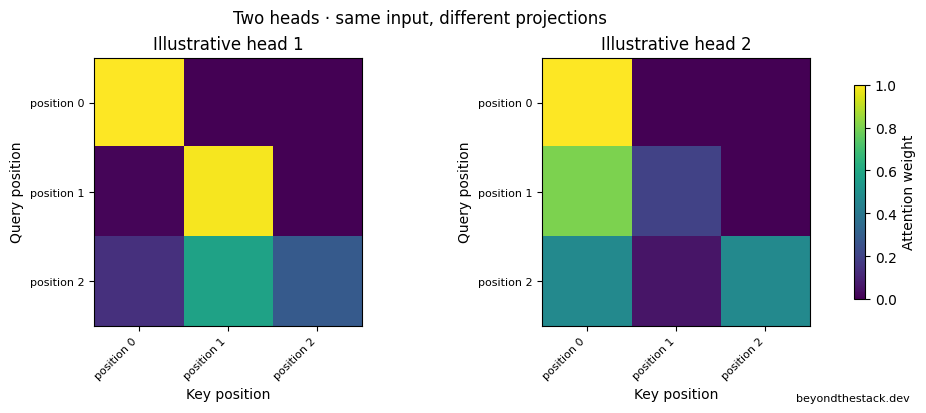

In [9]:
import matplotlib.pyplot as plt

def draw_attention(axis, weights, labels, title):
    image = axis.imshow(weights.detach().cpu().numpy(), vmin=0., vmax=1., cmap="viridis")
    axis.set_xticks(range(len(labels)), labels=labels, rotation=45, ha="right", fontsize=8)
    axis.set_yticks(range(len(labels)), labels=labels, fontsize=8)
    axis.set_xlabel("Key position")
    axis.set_ylabel("Query position")
    axis.set_title(title)
    return image

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for axis, result, title in zip(axes, (head_1, head_2), ("Illustrative head 1", "Illustrative head 2")):
    image = draw_attention(axis, result["weights (softmax-ed)"], position_labels, title)
fig.colorbar(image, ax=axes, label="Attention weight", shrink=0.8)
fig.suptitle("Two heads · same input, different projections")
fig.text(0.99, 0.01, "beyondthestack.dev", ha="right", fontsize=8)
plt.show()
plt.close(fig)

## 3 · Inspecting a trained SmolLM2 checkpoint
### 3.1 What exactly are we loading?
We now leave the invented matrices and load the base `HuggingFaceTB/SmolLM2-135M` checkpoint at revision `93efa2f097d58c2a74874c7e644dbc9b0cee75a2`. Its GPT-2-style tokenizer does not make the model GPT-2; its network uses a Llama-family implementation.

Use the eager attention backend so attention matrices can be returned. Run the transformer backbone with caching disabled, on CPU in float32. We do not generate text. Evaluation mode disables training behavior; explicitly disabling parameter gradients and using inference mode ensure no parameter update occurs.

The reconstruction below targets Transformers 4.57.6. Other versions can change internal APIs; the version check prevents silently treating different internals as equivalent.

In [10]:
from transformers import AutoTokenizer, AutoModel
assert version("transformers") == "4.57.6", "This instrumented example requires Transformers 4.57.6; see requirements.txt."

tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT, revision=REVISION, use_fast=True)
model = AutoModel.from_pretrained(
    CHECKPOINT, revision=REVISION, use_safetensors=True,
    dtype=torch.float32, attn_implementation="eager",
).to("cpu").eval()
model.requires_grad_(False)

config = model.config
print("Tokenizer:", type(tokenizer).__name__)
print("Backbone:", type(model).__name__)
print("Model revision:", config._commit_hash)
print("Attention backend:", config._attn_implementation)
print("Parameter dtype:", next(model.parameters()).dtype)
print("Layers:", config.num_hidden_layers)
print("Hidden width:", config.hidden_size)
print("Query heads:", config.num_attention_heads)
print("Key/value heads:", config.num_key_value_heads)
print("Head width:", config.hidden_size // config.num_attention_heads)
assert config._commit_hash == REVISION
assert (config.num_attention_heads, config.num_key_value_heads) == (9, 3)
assert config._attn_implementation == "eager"

Tokenizer: GPT2TokenizerFast
Backbone: LlamaModel
Model revision: 93efa2f097d58c2a74874c7e644dbc9b0cee75a2
Attention backend: eager
Parameter dtype: torch.float32
Layers: 30
Hidden width: 576
Query heads: 9
Key/value heads: 3
Head width: 64


**Grouped-query attention:** SmolLM2 has nine query heads but three key/value heads. Three query heads share each key/value head. Our earlier two-head example gave every head its own Q/K/V projections; this real model uses sharing. The projected head width is 64, not 576. We will account for this in the reconstruction rather than silently substituting conventional multi-head attention.

The actual first attention module receives vectors after input normalization and applies rotary position processing to queries and keys. These implementation steps matter for numerical agreement; their detailed mathematics is outside this notebook's explanation.

### 3.2 A controlled context comparison
Compare two work requests: `Review the delivery notification component for refactoring.` and `Review the customer churn number for Q3.` We select the shared token **' for' at position 5**: same ID and same position, but different preceding token IDs. It is a convenient structural control, not a word-sense benchmark.

A third input changes only the suffix after that position. It tests the causal restriction separately from the preceding-context comparison. All positions are zero-based; no automatic special tokens are inserted.

In [11]:
PROMPT_A = "Review the delivery notification component for refactoring."
PROMPT_B = "Review the customer churn number for Q3."
PROMPT_FUTURE_CONTROL = "Review the delivery notification component for testing."

def encode_prompt(text):
    return tokenizer(text, return_tensors="pt", add_special_tokens=False)

inputs_a = encode_prompt(PROMPT_A)
inputs_b = encode_prompt(PROMPT_B)
inputs_future_control = encode_prompt(PROMPT_FUTURE_CONTROL)
for label, text, inputs in [
    ("Example A: ", PROMPT_A, inputs_a), ("Example B: ", PROMPT_B, inputs_b),
    ("Future-only control", PROMPT_FUTURE_CONTROL, inputs_future_control),
]:
    ids = inputs["input_ids"][0].tolist()
    print(label, repr(text))
    print(list(enumerate(zip(tokenizer.convert_ids_to_tokens(ids), ids))),"\n")

Example A:  'Review the delivery notification component for refactoring.'
[(0, ('Review', 21465)), (1, ('Ġthe', 260)), (2, ('Ġdelivery', 7037)), (3, ('Ġnotification', 24408)), (4, ('Ġcomponent', 5077)), (5, ('Ġfor', 327)), (6, ('Ġref', 930)), (7, ('act', 471)), (8, ('oring', 1522)), (9, ('.', 30))] 

Example B:  'Review the customer churn number for Q3.'
[(0, ('Review', 21465)), (1, ('Ġthe', 260)), (2, ('Ġcustomer', 7742)), (3, ('Ġchurn', 36736)), (4, ('Ġnumber', 1230)), (5, ('Ġfor', 327)), (6, ('ĠQ', 1606)), (7, ('3', 35)), (8, ('.', 30))] 

Future-only control 'Review the delivery notification component for testing.'
[(0, ('Review', 21465)), (1, ('Ġthe', 260)), (2, ('Ġdelivery', 7037)), (3, ('Ġnotification', 24408)), (4, ('Ġcomponent', 5077)), (5, ('Ġfor', 327)), (6, ('Ġtesting', 3728)), (7, ('.', 30))] 



### 3.3 Inference: capture three distinct stages
We record:
- **Input embeddings:** rows retrieved from the checkpoint's table.
- **Attention-module output:** combined head outputs after the output projection, before the residual addition.
- **First block output:** after that block's residual additions and feed-forward processing; this is not attention alone.

Hooks also capture the actual normalized inputs, mask, and position data used by the first attention module. They are removed after each run. The model returns attention matrices for every layer; the comparison below uses layer 0 only.

```text
Incoming vectors
       │
       ▼
┌────────────── Transformer block ───────────────┐
│                                                │
│  Normalize                                     │
│       │                                        │
│       ▼                                        │
│  ┌────────── Attention module ──────────────┐  │
│  │  Combine heads and project their output  │  │
│  └──────────────────┬───────────────────────┘  │
│                     ▼                          │
│              attention_output                  │
│                     │                          │
│                     ▼                          │
│  Add incoming vectors (residual)                │
│                     │                          │
│                     ▼                          │
│  Normalize and apply feed-forward network       │
│                     │                          │
│                     ▼                          │
│  Add the vector from before feed-forward       │
│  processing (residual)                         │
│                                                │
└─────────────────────┬──────────────────────────┘
                      ▼
                block_output
                      │
                      ▼
           Next transformer block
```

In [12]:
selected_position = 5
selected_layer = 0
selected_head = 0

token_ids_a = inputs_a["input_ids"][0]
token_ids_b = inputs_b["input_ids"][0]
token_ids_future = inputs_future_control["input_ids"][0]
assert token_ids_a[selected_position].item() == token_ids_b[selected_position].item() == 327
assert tokenizer.decode([327]) == " for"
assert not torch.equal(token_ids_a[:selected_position], token_ids_b[:selected_position])
assert torch.equal(token_ids_a[:selected_position+1], token_ids_future[:selected_position+1])
print("Selected token:", repr(tokenizer.decode([token_ids_a[selected_position].item()])), "; selected ID:", token_ids_a[selected_position].item(), "; selected position:", selected_position, "\n")

first_block = model.layers[selected_layer]
first_attention = first_block.self_attn

def run_probe(inputs):
    captured = {}
    def capture_attention_input(module, args, kwargs):
        captured["attention_input"] = kwargs["hidden_states"].detach().clone()
        captured["position_embeddings"] = tuple(t.detach().clone() for t in kwargs["position_embeddings"])
        mask = kwargs.get("attention_mask")
        captured["mask"] = None if mask is None else mask.detach().clone()
    def capture_attention_output(module, args, output):
        captured["attention_output"] = output[0].detach().clone()
    def capture_block_output(module, args, output):
        captured["block_output"] = output.detach().clone()
    handles = [
        first_attention.register_forward_pre_hook(capture_attention_input, with_kwargs=True),
        first_attention.register_forward_hook(capture_attention_output),
        first_block.register_forward_hook(capture_block_output),
    ]
    try:
        with torch.inference_mode():
            captured["input_embeddings"] = model.get_input_embeddings()(inputs["input_ids"]).clone()
            result = model(**inputs, output_attentions=True, use_cache=False, return_dict=True)
            captured["attention_weights"] = result.attentions[selected_layer].detach().clone()
    finally:
        for handle in handles:
            handle.remove()
    return captured

probe_a = run_probe(inputs_a)
probe_b = run_probe(inputs_b)
probe_future = run_probe(inputs_future_control)
for name in ("input_embeddings", "attention_input", "attention_weights", "attention_output", "block_output"):
    print(name, tuple(probe_a[name].shape))

for probe in (probe_a, probe_b, probe_future):
    weights = probe["attention_weights"]
    future = torch.triu(torch.ones(weights.shape[-2:], dtype=torch.bool), diagonal=1)
    assert torch.count_nonzero(weights[..., future]).item() == 0
    torch.testing.assert_close(weights.sum(-1), torch.ones_like(weights.sum(-1)), atol=1e-6, rtol=1e-6)

Selected token: ' for' ; selected ID: 327 ; selected position: 5 

input_embeddings (1, 10, 576)
attention_input (1, 10, 576)
attention_weights (1, 9, 10, 10)
attention_output (1, 10, 576)
block_output (1, 10, 576)


### 3.4 Reconstruct the actual first attention module
**Purpose**: This verification bridges the small calculation and a real implementation. It uses the actual normalized input, trained projections, rotary-position helper, shared key/value heads, and mask. It does not replace the complete transformer forward pass.

    SmolLM2 applies **rotary position processing** to queries and keys before calculating scores. The helper `apply_rotary_pos_emb` uses position-dependent information to rotate pairs of values in those vectors. This helps attention account for token positions and their relative distances; it does not transform the values or change the learned projection matrices.

Position processing and the **causal mask** have different jobs: the former provides position information, while the latter prevents a position from attending to later positions. SmolLM2 uses both, but rotary position processing is not required specifically because a model is causal; other models can use different position methods.

In **conventional multi-head attention (MHA)**, each query head has its own key and value heads. SmolLM2 uses **grouped-query attention (GQA)**: three query heads share each key/value head.

```text
Query heads:       Q0 Q1 Q2 | Q3 Q4 Q5 | Q6 Q7 Q8
                    │  │  │    │  │  │    │  │  │
Shared K/V head:    0  0  0 |  1  1  1 |  2  2  2
```

The `repeat_kv` helper arranges the three key heads as nine sets for the calculation; it does the same for the value heads:

```text
Learned key heads:       K0       K1       K2
                         ↓        ↓        ↓
Arranged for queries:  K0 K0 K0  K1 K1 K1  K2 K2 K2
```

Each query head can now be paired with a corresponding set of keys and values. The repeated sets come from the same three learned key/value heads; they are not independently learned heads. This does not change the model's GQA design or its checkpoint.

The model's **eager attention** implementation performs these operations explicitly and exposes attention weights for inspection. This reconstruction uses its `repeat_kv` helper to match that calculation; other implementations may handle sharing more efficiently without explicitly repeating the sets.

PyTorch Linear stores weights as (output width, input width), so applying a layer corresponds to multiplication by the stored weight's transpose. The conceptual XW notation used earlier chooses the other storage orientation.

We compare both the reconstructed attention weights and the full projected attention output against values captured during the model's forward pass.

In [13]:
from transformers.models.llama.modeling_llama import apply_rotary_pos_emb, repeat_kv

with torch.inference_mode():
    current_input = probe_a["attention_input"]
    batch_size, real_sequence_length, _ = current_input.shape
    real_head_width = first_attention.head_dim
    queries = first_attention.q_proj(current_input).view(
        batch_size, real_sequence_length, config.num_attention_heads, real_head_width
    ).transpose(1, 2)
    keys = first_attention.k_proj(current_input).view(
        batch_size, real_sequence_length, config.num_key_value_heads, real_head_width
    ).transpose(1, 2)
    values = first_attention.v_proj(current_input).view(
        batch_size, real_sequence_length, config.num_key_value_heads, real_head_width
    ).transpose(1, 2)

    # Apply the checkpoint's actual positional processing before scoring.
    queries, keys = apply_rotary_pos_emb(queries, keys, *probe_a["position_embeddings"])
    repeated_keys = repeat_kv(keys, first_attention.num_key_value_groups)
    repeated_values = repeat_kv(values, first_attention.num_key_value_groups)
    scores = (queries @ repeated_keys.transpose(-2, -1)) * first_attention.scaling
    if probe_a["mask"] is not None:
        scores = scores + probe_a["mask"][..., :real_sequence_length]
    reconstructed_weights = torch.softmax(scores, dim=-1, dtype=torch.float32).to(queries.dtype)
    per_head_output = reconstructed_weights @ repeated_values
    concatenated_output = per_head_output.transpose(1, 2).contiguous().reshape(
        batch_size, real_sequence_length, config.num_attention_heads * real_head_width
    )
    reconstructed_output = first_attention.o_proj(concatenated_output)

torch.testing.assert_close(reconstructed_weights, probe_a["attention_weights"], atol=1e-6, rtol=1e-5)
torch.testing.assert_close(reconstructed_output, probe_a["attention_output"], atol=1e-6, rtol=1e-5)
print("# (batch, heads, token positions, values per head)")
print("Q shape:", tuple(queries.shape))
print("K/V before sharing:", tuple(keys.shape), tuple(values.shape))
print("K/V after sharing:", tuple(repeated_keys.shape), tuple(repeated_values.shape))
print("Per-head output:", tuple(per_head_output.shape))
print("Output after concatenation and projection:", tuple(reconstructed_output.shape))
print("Max weight reconstruction error:", (reconstructed_weights - probe_a["attention_weights"]).abs().max().item())
print("Max module-output reconstruction error:", (reconstructed_output - probe_a["attention_output"]).abs().max().item())
print("Verified reconstruction of layer 0 attention, including position processing and GQA.")

# (batch, heads, token positions, values per head)
Q shape: (1, 9, 10, 64)
K/V before sharing: (1, 3, 10, 64) (1, 3, 10, 64)
K/V after sharing: (1, 9, 10, 64) (1, 9, 10, 64)
Per-head output: (1, 9, 10, 64)
Output after concatenation and projection: (1, 10, 576)
Max weight reconstruction error: 0.0
Max module-output reconstruction error: 0.0
Verified reconstruction of layer 0 attention, including position processing and GQA.


### 3.5 Same input embedding, different preceding context (different attention and block outputs)
Compare the selected position (token at index 5 -> ` for`) at the same layer in A and B. The input embedding should match exactly. Later differences show sensitivity to the supplied preceding tokens in this controlled example; they do not establish that the model understands either review task.

The printed coordinates are excerpts (first four values, rounded); the norms and assertions use the full vectors. A first-block output includes more than the attention module.

In [14]:
for stage in ("input_embeddings", "attention_output", "block_output"):
    vector_a = probe_a[stage][0, selected_position]
    vector_b = probe_b[stage][0, selected_position]
    print("\n" + stage, "selected token is ` for`")
    print("Example A: first 4:", [round(x, 5) for x in vector_a[:4].tolist()])
    print("Example B: first 4:", [round(x, 5) for x in vector_b[:4].tolist()])
    print("Full-vector L2 difference:", torch.linalg.vector_norm(vector_a-vector_b).item())

assert torch.equal(probe_a["input_embeddings"][0,selected_position], probe_b["input_embeddings"][0,selected_position])
assert not torch.allclose(probe_a["attention_output"][0,selected_position], probe_b["attention_output"][0,selected_position])
assert not torch.allclose(probe_a["block_output"][0,selected_position], probe_b["block_output"][0,selected_position])

print("\nLayer 0, query head 0: weights for selected query over permitted keys")
for label, inputs, probe in [("A", inputs_a, probe_a), ("B", inputs_b, probe_b)]:
    pieces = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0].tolist())
    weights = probe["attention_weights"][0, selected_head, selected_position]
    print(label, [(i, pieces[i], round(weights[i].item(), 6)) for i in range(selected_position+1)])
    print("Weight on future positions:", weights[selected_position+1:].sum().item())


input_embeddings selected token is ` for`
Example A: first 4: [-0.0603, 0.06787, -0.00369, 0.11621]
Example B: first 4: [-0.0603, 0.06787, -0.00369, 0.11621]
Full-vector L2 difference: 0.0

attention_output selected token is ` for`
Example A: first 4: [0.00292, -0.00219, 0.00685, 0.03227]
Example B: first 4: [0.0051, 0.00711, 0.00682, 0.02801]
Full-vector L2 difference: 0.30006128549575806

block_output selected token is ` for`
Example A: first 4: [-1.82567, 0.27969, 0.22665, 2.09188]
Example B: first 4: [-2.07683, 0.28072, 0.23695, 2.15192]
Full-vector L2 difference: 1.6937764883041382

Layer 0, query head 0: weights for selected query over permitted keys
A [(0, 'Review', 0.059292), (1, 'Ġthe', 0.335959), (2, 'Ġdelivery', 0.161475), (3, 'Ġnotification', 0.138363), (4, 'Ġcomponent', 0.296165), (5, 'Ġfor', 0.008747)]
Weight on future positions: 0.0
B [(0, 'Review', 0.077193), (1, 'Ġthe', 0.437387), (2, 'Ġcustomer', 0.086235), (3, 'Ġchurn', 0.11048), (4, 'Ġnumber', 0.277319), (5, 'Ġfor'

### 3.6 A separate check: changing only future text
Example A and the future-only control (example 3) have exactly the same token IDs through position 5. Their later text differs. For causal attention, representations through position 5 must remain equal within numerical tolerance.

This is separate from the preceding-context comparison. Also check the opening Review position in A versus B: different later requests do not change its first-block representation.

In [15]:
for stage in ("input_embeddings", "attention_output", "block_output"):
    original_prefix = probe_a[stage][:,:selected_position+1]
    future_changed_prefix = probe_future[stage][:,:selected_position+1]
    torch.testing.assert_close(original_prefix, future_changed_prefix, atol=1e-6, rtol=1e-5)
    print(stage, "future-only change, max prefix difference:",
          (original_prefix-future_changed_prefix).abs().max().item())
torch.testing.assert_close(probe_a["block_output"][:,0], probe_b["block_output"][:,0], atol=1e-6, rtol=1e-5)
print("Opening Review: first-block outputs match despite different later words.")
print("All real-model probes used fixed parameters; no optimizer or cache was used.")

input_embeddings future-only change, max prefix difference: 0.0
attention_output future-only change, max prefix difference: 0.0
block_output future-only change, max prefix difference: 0.0
Opening Review: first-block outputs match despite different later words.
All real-model probes used fixed parameters; no optimizer or cache was used.


### 3.7 Measured attention heatmaps
Layer 0, query head 0 is chosen in advance for inspection, not selected because it looks meaningful. The two panels share a 0–1 scale. Each axis label includes the zero-based token position and raw tokenizer piece; Ġ marks a space.

The upper triangle is zero because future keys are masked. The selected query is position 5. Weight differences do not identify named head roles, causal importance to a final answer, or general model quality.

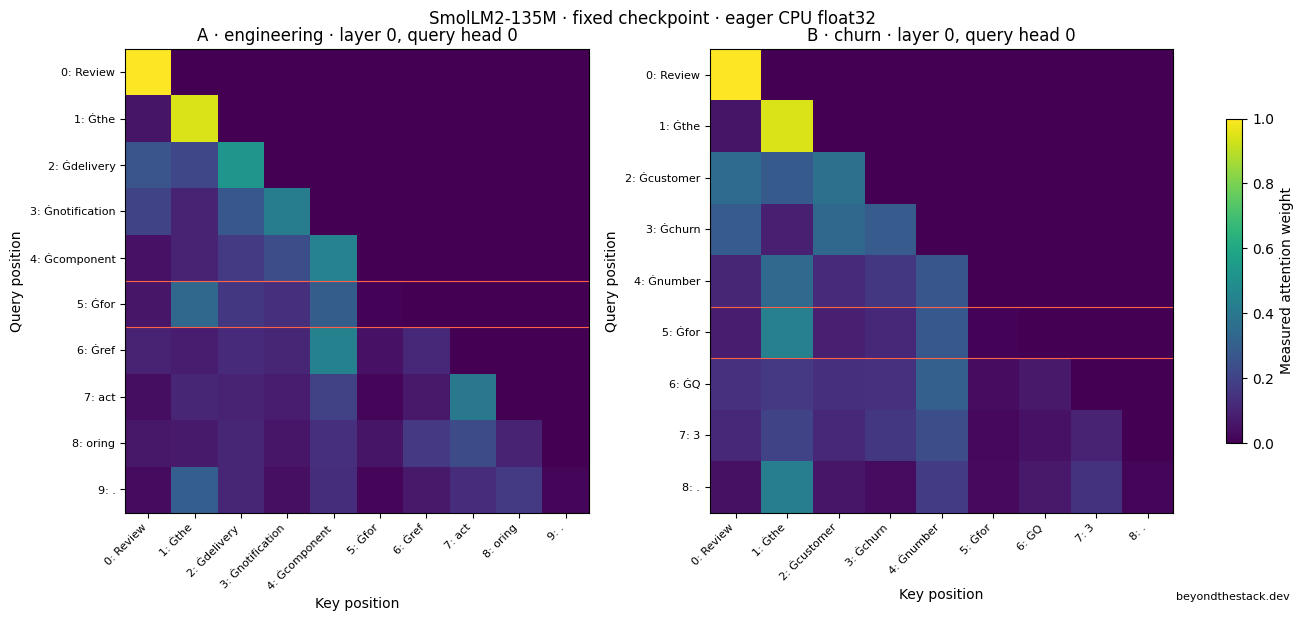

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
for axis, label, inputs, probe in zip(axes, ("A · engineering", "B · churn"), (inputs_a, inputs_b), (probe_a, probe_b)):
    pieces = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0].tolist())
    labels = [f"{i}: {piece}" for i, piece in enumerate(pieces)]
    image = draw_attention(axis, probe["attention_weights"][0, selected_head], labels,
                           f"{label} · layer 0, query head 0")
    axis.axhline(selected_position-0.5, color="tomato", linewidth=0.8)
    axis.axhline(selected_position+0.5, color="tomato", linewidth=0.8)
fig.colorbar(image, ax=axes, label="Measured attention weight", shrink=0.7)
fig.suptitle("SmolLM2-135M · fixed checkpoint · eager CPU float32")
fig.text(0.99, 0.01, "beyondthestack.dev", ha="right", fontsize=8)
plt.show()
plt.close(fig)

## 4 · Observations and boundaries
| Statement | Evidence | Qualification |
| --- | --- | --- |
| Query/key scores become mixing weights | Illustrative scaled, masked softmax calculation | Invented projections; not semantic evidence |
| One head combines value vectors | Illustrative attention weights multiplied by the value matrix | Head output is not block output |
| Several heads can calculate different mixtures | Two-head example with concatenation and output projection | No named specialization is inferred |
| SmolLM2 shares keys/values across query-head groups | Configuration and tensor shapes | Specific pinned checkpoint |
| Real attention follows the inspected calculation | Reconstruction matches captured module weights and output | Includes normalization input, RoPE, GQA, and actual mask; version-specific |
| Identical token ID and position can yield different later vectors | Position-5 A/B comparison | Preceding context differs; one controlled example |
| Future text cannot affect earlier causal representations | Future-only control and opening-position check | Fixed parameters; numerical tolerance stated |

### Attention within a transformer block
The illustrated attention module ends after combining heads and applying the output projection. SmolLM2's block also includes normalization, residual additions, and a feed-forward network. The measured block output includes those operations. We do not derive them here.

Input order also matters. The real-model reconstruction uses rotary position processing; the illustrative matrices isolate the attention arithmetic rather than claim to reproduce every architectural detail.

### What to explore later
During causal generation, keys and values from earlier positions can be reused rather than recomputed. That is the motivation for KV caching; this notebook disables it to inspect straightforward full-sequence passes. Cache memory, prefill/decode costs, and alternative attention architectures belong in separate experiments.

### References and reproducibility
- [Attention Is All You Need, sections 3.2–3.3](https://arxiv.org/html/1706.03762v7)
- [GQA paper](https://arxiv.org/abs/2305.13245)
- [Pinned SmolLM2 configuration](https://huggingface.co/HuggingFaceTB/SmolLM2-135M/blob/93efa2f097d58c2a74874c7e644dbc9b0cee75a2/config.json)
- [Transformers 4.57.6 Llama implementation](https://github.com/huggingface/transformers/blob/v4.57.6/src/transformers/models/llama/modeling_llama.py)
- [KV-cache explanation](https://huggingface.co/docs/transformers/v4.57.1/cache_explanation)

Saved output records one execution, not a universal result. Rerun in a fresh kernel to reproduce it. The pinned checkpoint and direct dependencies are recorded; requirements.txt is not a full transitive lockfile. The model weights are not included. The notebook displays only short numerical excerpts and its own plots; inputs are synthetic.